# Buried defects in a 3D-NAND stack — bright-field detectability against depth
A simplified 3D-NAND memory stack: alternating tungsten and oxide layers on a silicon
substrate, pierced by a square lattice of conical plug holes, each lined with a nitride
liner, a poly-silicon channel and an oxide core. Buried defects are placed one at a time
at the central plug: a tungsten bridge into the channel at four depths, a void in the
stack next to the plug near the top, and tungsten residue at the bottom of the plug.

A plane wave lights the structure from above; the reflected field is imaged by a
microscope objective of numerical aperture NA, focused on the top of the stack, into a
bright-field image. Each defect's image minus the defect-free one is the difference
image an inspection tool looks at, and its peak is the defect's signal. The imaging here
is coherent, one wavelength and one polarization, where a real tool uses broadband,
partially coherent illumination; the full-wave solve is the same in both cases.

The example shows:
* the stack and the defects in cross-section;
* the field inside the stack, which enters mainly through the plug holes and fades with
  depth;
* the difference image of every defect and the signal against the defect's depth.

The cell of plugs repeats periodically in x and y, so the single defect is one per cell;
the absorbing boundaries are in z, with the silicon made effectively infinite below.

Size: 8 solves, the largest 34.56 Mvoxel including boundaries, 1.80 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from wsutils import output_dir, plane_wave
from wavesimpro import configure, create_monitor, simulate

NAME = "mx_nand_defects"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

### Parameters
Lengths in μm. The z axis is depth: light enters at z = 0, the stack lies below an air
gap, the silicon substrate below the stack.

In [2]:
wavelength = 0.55
pixel_size = 0.010
NA = 0.9                                  # objective numerical aperture, imaging in air
threshold = 1e-7                          # solver residual; the difference images need two runs converged alike

MATERIALS = ["air", "SiO2", "Si3N4", "Si", "W"]
INDEX = np.array([1.0, 1.46, 2.02, 4.08 + 0.04j, 3.5 + 2.7j], dtype=np.complex64)   # near 550 nm
AIR, SIO2, SI3N4, SI, W = range(5)

pitch = 0.24                              # plug lattice pitch, square lattice
n_cells = 10                              # plugs per side of the periodic cell
t_w, t_ox = 0.030, 0.030                  # tungsten and oxide layer thicknesses
n_pairs = 16
r_top, r_bottom = 0.065, 0.050            # plug radius at the top and the bottom of the stack: conical
t_liner, t_channel = 0.020, 0.020         # nitride liner and poly-Si channel on the plug wall; oxide core inside

z_air = 0.40                              # air above the stack
t_sub = 0.24                              # silicon below the stack, continued by the absorbing boundary
z_src = 0.10                              # depth of the source sheet
z_meas = 0.25                             # plane where the reflected field is read
boundary_width = 2.2                      # absorbing boundary in z, 4 λ

bridge_pairs = [0, 2, 5, 8]               # tungsten bridge: the plug filled with W over this tungsten layer
void_pair, void_radius = 1, 0.040         # void: an air sphere centred in this tungsten layer, between the central plug and its neighbour

cell = n_cells * pitch
z_stack0, z_stack1 = z_air, z_air + n_pairs * (t_w + t_ox)
sim_size = np.array([cell, cell, z_stack1 + t_sub])
center = np.array([cell / 2, cell / 2])   # the central plug
k0 = 2 * np.pi / wavelength
nx, ny, nz = (int(round(v / pixel_size)) for v in sim_size)
x = (np.arange(nx) + 0.5) * pixel_size
y = (np.arange(ny) + 0.5) * pixel_size
z = (np.arange(nz) + 0.5) * pixel_size
iz_meas = int(z_meas / pixel_size)


def layer_top(pair):
    """Depth of the top of the tungsten layer of this pair."""
    return z_stack0 + pair * (t_w + t_ox)


print(f"Cell {sim_size} um = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.1f} Mvoxel without boundaries), {wavelength / pixel_size:.0f} voxels per vacuum wavelength")
print(f"Stack: {n_pairs} W/SiO2 pairs of {1e3 * t_w:.0f}/{1e3 * t_ox:.0f} nm = {1e3 * (z_stack1 - z_stack0):.0f} nm, "
      f"{n_cells}x{n_cells} plugs at {1e3 * pitch:.0f} nm pitch, radius {1e3 * r_top:.0f} -> {1e3 * r_bottom:.0f} nm")
print(f"Objective NA {NA}: resolution {wavelength / (2 * NA) * 1e3:.0f} nm")

Cell [2.4 2.4 1.6] um = 240x240x160 voxels (9.2 Mvoxel without boundaries), 55 voxels per vacuum wavelength
Stack: 16 W/SiO2 pairs of 30/30 nm = 960 nm, 10x10 plugs at 240 nm pitch, radius 65 -> 50 nm
Objective NA 0.9: resolution 306 nm


### Stack and defects
`build(defect, pair)` returns a material-code map; the permittivity is the squared index
of each code. The plugs sit on the lattice sites, one of them at the cell centre, and
the cell edge cuts the outermost row in half, which the periodic boundary joins up
again. Each case is a name, a defect type and the pair of layers it sits in.

In [3]:
def build(defect=None, pair=None):
    code = np.full((nx, ny, nz), AIR, dtype=np.int8)
    for p in range(n_pairs):
        code[:, :, (z >= layer_top(p)) & (z < layer_top(p) + t_w)] = W
        code[:, :, (z >= layer_top(p) + t_w) & (z < layer_top(p + 1))] = SIO2
    code[:, :, z >= z_stack1] = SI

    dx = (x[:, None] + pitch / 2) % pitch - pitch / 2
    dy = (y[None, :] + pitch / 2) % pitch - pitch / 2
    r = np.sqrt(dx ** 2 + dy ** 2)[:, :, None]
    in_stack = (z >= z_stack0) & (z < z_stack1)
    radius = np.where(in_stack, r_top + (r_bottom - r_top) * (z - z_stack0) / (z_stack1 - z_stack0), 0)[None, None, :]
    code[r < radius] = SI3N4
    code[r < radius - t_liner] = SI
    code[r < radius - t_liner - t_channel] = SIO2

    central = np.sqrt((x[:, None] - center[0]) ** 2 + (y[None, :] - center[1]) ** 2)[:, :, None] < radius
    if defect == "bridge":
        code[central & ((z >= layer_top(pair)) & (z < layer_top(pair) + t_w))[None, None, :]] = W
    elif defect == "residue":
        code[central & (z >= layer_top(pair))[None, None, :]] = W
    elif defect == "void":
        c = (center[0] + pitch / 2, center[1], layer_top(pair) + t_w / 2)
        sphere = ((x[:, None, None] - c[0]) ** 2 + (y[None, :, None] - c[1]) ** 2 + (z[None, None, :] - c[2]) ** 2) < void_radius ** 2
        code[sphere] = AIR
    return code


CASES = {f"bridge {1e3 * (layer_top(p) - z_stack0):.0f} nm": ("bridge", p) for p in bridge_pairs}
CASES[f"void {1e3 * (layer_top(void_pair) + t_w / 2 - z_stack0):.0f} nm"] = ("void", void_pair)
CASES[f"residue {1e3 * (layer_top(n_pairs - 1) - z_stack0):.0f} nm"] = ("residue", n_pairs - 1)
depth = {name: 1e3 * (layer_top(pair) + t_w / 2 - z_stack0) for name, (_, pair) in CASES.items()}   # defect centre below the stack top, nm

codes = {"reference": build()}
for name, (defect, pair) in CASES.items():
    codes[name] = build(defect, pair)
    changed = int(np.sum(codes[name] != codes["reference"]))
    print(f"{name}: {changed} voxels changed, the volume of a {1e3 * pixel_size * changed ** (1 / 3):.0f} nm cube")

bridge 0 nm: 372 voxels changed, the volume of a 72 nm cube
bridge 120 nm: 360 voxels changed, the volume of a 71 nm cube
bridge 300 nm: 336 voxels changed, the volume of a 70 nm cube
bridge 480 nm: 336 voxels changed, the volume of a 70 nm cube
void 75 nm: 268 voxels changed, the volume of a 64 nm cube
residue 900 nm: 480 voxels changed, the volume of a 78 nm cube


### Setup figures
The defect-free stack through the central row of plugs and in a top cut through a
tungsten layer; then one bridge, the void and the residue, zoomed on the central plug.

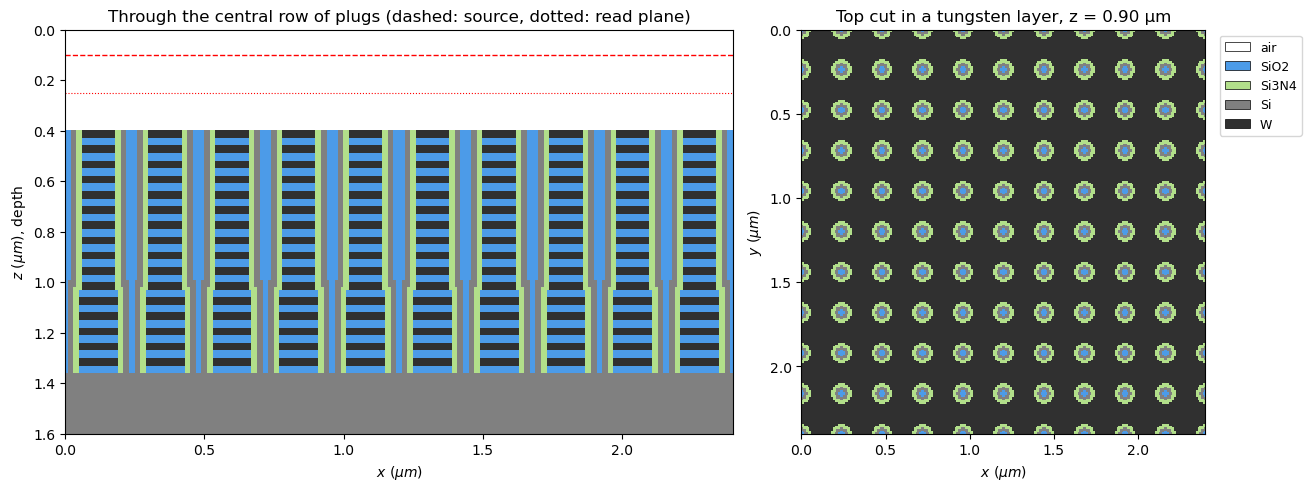

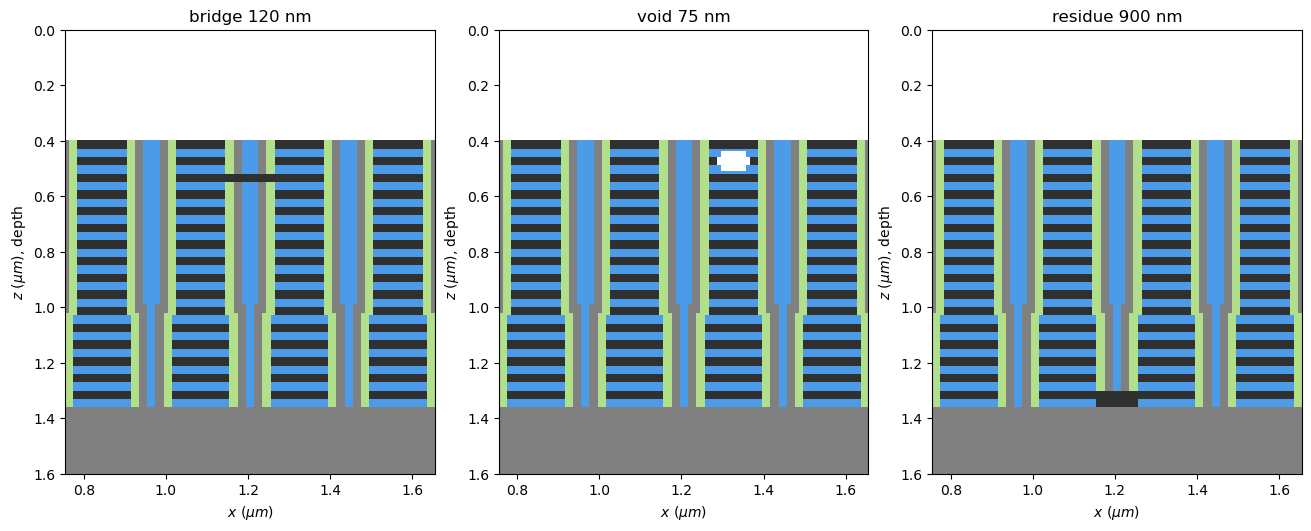

In [4]:
MAT_COLORS = ["white", "#4c9be8", "#b2df8a", "#808080", "#303030"]
mat_cmap, mat_norm = ListedColormap(MAT_COLORS), BoundaryNorm(np.arange(-0.5, 5.5), 5)
legend = [Patch(facecolor=c, edgecolor="k", lw=0.5, label=m) for c, m in zip(MAT_COLORS, MATERIALS)]
iy_c = int(center[1] / pixel_size)
iz_w = int((layer_top(bridge_pairs[-1]) + t_w / 2) / pixel_size)   # inside a tungsten layer

fig, (ax_s, ax_t) = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.6, 1]})
ax_s.imshow(codes["reference"][:, iy_c, :].T, cmap=mat_cmap, norm=mat_norm, extent=[0, cell, sim_size[2], 0], aspect="auto", interpolation="nearest")
ax_s.axhline(z_src, color="red", ls="--", lw=1)
ax_s.axhline(z_meas, color="red", ls=":", lw=0.8)
ax_s.set_xlabel(r"$x~(\mu m)$")
ax_s.set_ylabel(r"$z~(\mu m)$, depth")
ax_s.set_title("Through the central row of plugs (dashed: source, dotted: read plane)")
ax_t.imshow(codes["reference"][:, :, iz_w].T, cmap=mat_cmap, norm=mat_norm, extent=[0, cell, cell, 0], interpolation="nearest")
ax_t.set_xlabel(r"$x~(\mu m)$")
ax_t.set_ylabel(r"$y~(\mu m)$")
ax_t.set_title(f"Top cut in a tungsten layer, z = {z[iz_w]:.2f} μm")
ax_t.legend(handles=legend, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
fig.savefig(f"{OUTPUT_DIR}/nand_setup.png", dpi=200)

zoom = 0.45
ix0, ix1 = int((center[0] - zoom) / pixel_size), int((center[0] + zoom) / pixel_size)
shown = [list(CASES)[1], list(CASES)[-2], list(CASES)[-1]]
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), constrained_layout=True)
for ax, name in zip(axes, shown):
    ax.imshow(codes[name][ix0:ix1, iy_c, :].T, cmap=mat_cmap, norm=mat_norm, interpolation="nearest",
              extent=[x[ix0], x[ix1], sim_size[2], 0], aspect="auto")
    ax.set_title(name)
    ax.set_xlabel(r"$x~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$, depth")
fig.savefig(f"{OUTPUT_DIR}/nand_defects.png", dpi=200)

### Source
A uniform sheet across the periodic cell at normal incidence, polarized along x.

In [5]:
source = plane_wave(shape=((nx + 0.5) * pixel_size, (ny + 0.5) * pixel_size), origin="topleft",
                    position=(0, 0.0, 0.0, z_src), source_plane="xy", pixel_size=pixel_size)
print(f"Source {source[0].shape} at voxel {tuple(int(p) for p in source[1])}")

Source (1, 240, 240, 1) at voxel (0, 0, 0, 10)


### Solve
Air alone for the incident field, the defect-free stack, and one solve per case. Each
returns only the read plane and the cut through the central row, as two monitors.

In [6]:
def layer_monitor(name, axis, index):
    """The voxel layer ``index`` along ``axis``, over the whole cell. The monitor box is
    half a voxel thick around the layer's centre, so it holds that layer alone; voxel i on
    an n-voxel axis sits at (i + 0.5 - n/2) * pixel_size in domain-centred coordinates."""
    a = "xyz".index(axis)
    centre, extent = [0.0, 0.0, 0.0], [n * pixel_size for n in (nx, ny, nz)]
    centre[a] = (index + 0.5 - (nx, ny, nz)[a] / 2) * pixel_size
    extent[a] = pixel_size / 2
    return create_monitor(name=name, center_x=centre[0], center_y=centre[1], center_z=centre[2],
                          size_x=extent[0], size_y=extent[1], size_z=extent[2])


monitors = [layer_monitor("plane", "z", iz_meas), layer_monitor("side", "y", iy_c)]


def solve(code):
    start = time()
    (plane, side), iterations, residual = simulate(
        permittivity=(INDEX[code] ** 2).astype(np.complex64), sources=[source], wavelength=wavelength,
        pixel_size=pixel_size, boundary_width=boundary_width, periodic=(True, True, False),
        threshold=threshold, monitors=monitors)
    print(f"  {time() - start:.1f} s, {iterations} iterations, residual {residual:.1e}")
    return {"plane": plane.reshape(3, nx, ny), "side": np.sqrt(np.sum(np.abs(side.reshape(3, nx, nz)) ** 2, axis=0))}


fields = {}
print("air")
fields["air"] = solve(np.full((nx, ny, nz), AIR, dtype=np.int8))
for name, code in codes.items():
    print(name)
    fields[name] = solve(code)
np.savez(f"{OUTPUT_DIR}/nand_fields.npz", **{f"{name}_{k}": v for name, f in fields.items() for k, v in f.items()})

air

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 4218e16d-fa2f-4cab-9bf8-deeb6e12de8a
  Version   : 51e0d3d2-f0a1-42c3-847b-c7a5f9c5cc36
  Command   : 1afc9f82-e577-4bec-9c6c-c72bb0b5dfb0
  Mode      : Maxwell (vectorial)
  Domain    : 240x240x160 voxels  lambda=0.55 um  dx=0.010 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-07  max iter: 100000
  ------------------------------------------------------
  43.8 s, 39 iterations, residual 4.9e-08
reference

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : d3e3191f-b202-4d9a-a0a1-f5cfd4a054a4
  Version   : 9a6e4d4b-e39d-44b7-9552-fc0f42c0f4a0
  Command   : 6ca15b7b-d96f-40a8-8e5d-5ea12d9b1e9d
  Mode      : Maxwell (vectorial)
  Domain    : 240x240x160 voxels  lambda=0.55 um  dx=0.010 um
  Engine    : Any (

### Figure 1: field in the stack
|E| through the central row of plugs, defect-free. The tungsten layers keep the light
out of the stack except through the plugs, and it fades by about a decade every few
layers: a deep defect sees little light and sends little back.

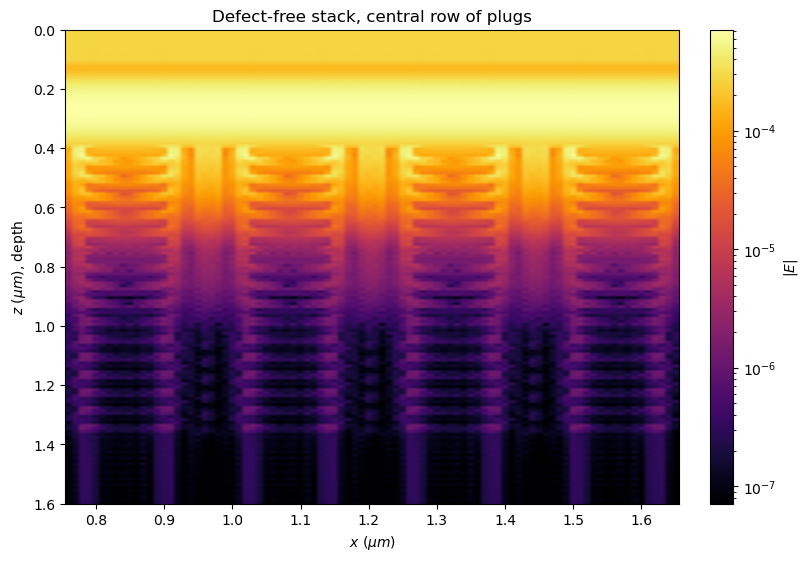

In [7]:
side = fields["reference"]["side"]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
im = ax.imshow(side[ix0:ix1].T, cmap="inferno", aspect="auto", extent=[x[ix0], x[ix1], sim_size[2], 0],
               norm=colors.LogNorm(vmin=side.max() * 1e-4, vmax=side.max()))
ax.set_xlabel(r"$x~(\mu m)$")
ax.set_ylabel(r"$z~(\mu m)$, depth")
ax.set_title("Defect-free stack, central row of plugs")
fig.colorbar(im, ax=ax, fraction=0.04).set_label(r"$|E|$")
fig.savefig(f"{OUTPUT_DIR}/nand_field.png", dpi=200)

### Bright-field images and defect signals
The reflected field on the read plane is the stack field minus the air field. Its
angular spectrum is propagated to the top of the stack, where the objective is focused,
cut at the pupil |sin θ| ≤ NA and transformed back: the coherent image, |E|² summed over
the components. The plug lattice is finer than the wavelength, so the defect-free image
is featureless and only a defect leaves a mark.

Each difference image is (defect − reference) / mean reference intensity. Its uniform
part, the change of the specular reflection, is removed and listed on its own: it is
at the level two runs can differ by at the solver threshold and carries no position.
The signal is the peak of what remains; a signal no larger than the offsets is at that
numerical level too, not a defect being seen.


case              depth nm  peak signal        rms     offset
bridge 0 nm             15     1.11e-01   1.66e-02   2.61e-03
bridge 120 nm          135     1.94e-02   2.93e-03   4.05e-04
bridge 300 nm          315     9.07e-05   1.84e-05   2.78e-08
bridge 480 nm          495     4.42e-06   1.21e-06  -2.52e-07
void 75 nm              75     1.74e-02   2.64e-03   4.59e-04
residue 900 nm         915     1.56e-07   6.78e-08   3.79e-07
Saved output/mx_nand_defects/nand_setup.png, _defects.png, _field.png, _images.png


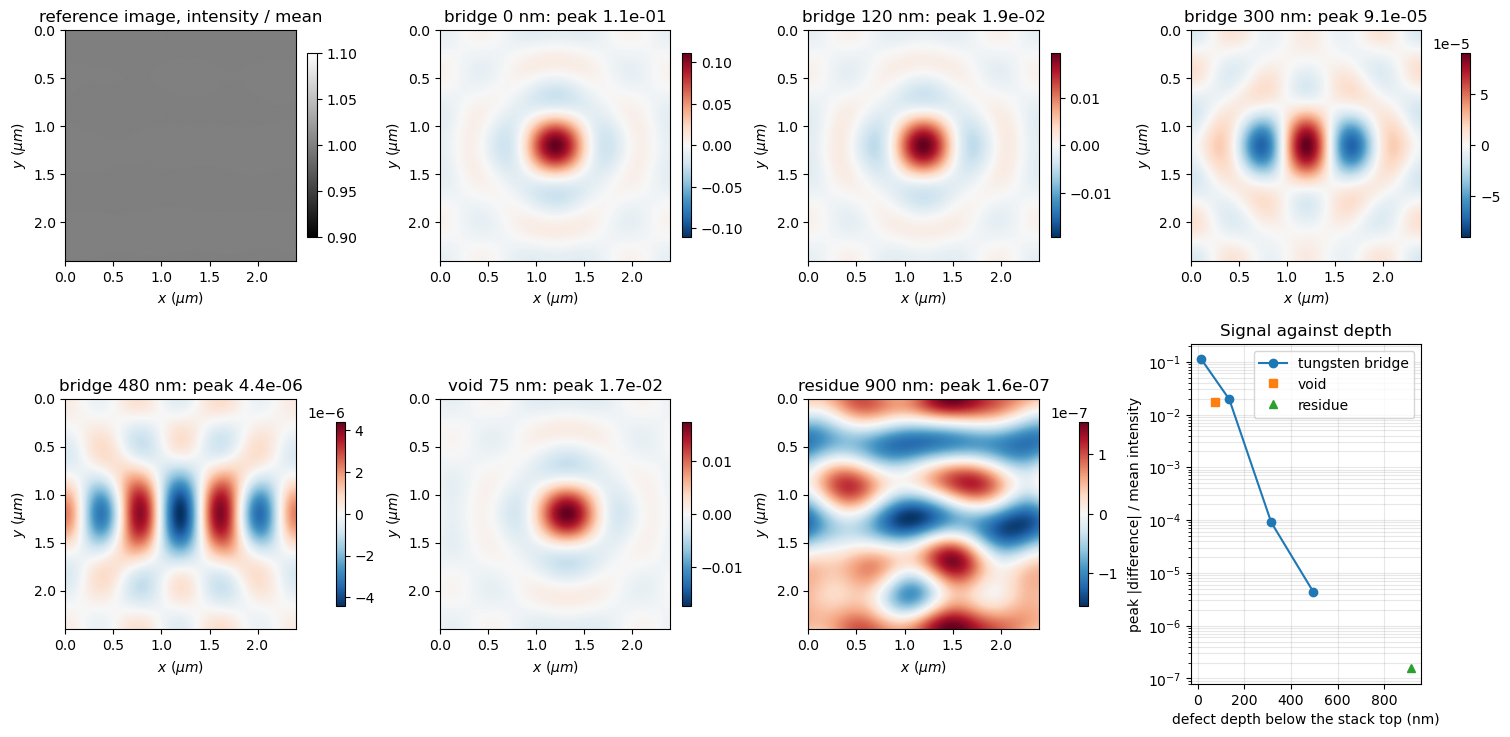

In [8]:
kx = 2 * np.pi * np.fft.fftfreq(nx, pixel_size) / k0
ky = 2 * np.pi * np.fft.fftfreq(ny, pixel_size) / k0
s2 = kx[:, None] ** 2 + ky[None, :] ** 2
pupil = s2 <= NA ** 2
refocus = np.exp(-1j * k0 * np.sqrt(np.where(pupil, 1 - s2, 0)) * (z_stack0 - z_meas))   # up-going waves, read plane -> stack top


def bright_field_image(u_plane):
    spectrum = np.fft.fft2(u_plane, axes=(1, 2)) * (pupil * refocus)
    return np.sum(np.abs(np.fft.ifft2(spectrum, axes=(1, 2))) ** 2, axis=0)


images = {name: bright_field_image(fields[name]["plane"] - fields["air"]["plane"]) for name in codes}
i_mean = images["reference"].mean()
offset, diffs = {}, {}
for name in CASES:
    d = (images[name] - images["reference"]) / i_mean
    offset[name] = d.mean()
    diffs[name] = d - offset[name]
signal_peak = {name: np.abs(d).max() for name, d in diffs.items()}

fig, axes = plt.subplots(2, 4, figsize=(15, 7.6), constrained_layout=True)
im = axes[0, 0].imshow(images["reference"].T / i_mean, cmap="gray", extent=[0, cell, cell, 0], vmin=0.9, vmax=1.1)
axes[0, 0].set_title("reference image, intensity / mean")
fig.colorbar(im, ax=axes[0, 0], fraction=0.04)
for ax, name in zip(axes.flat[1:], CASES):
    v = signal_peak[name]
    im = ax.imshow(diffs[name].T, cmap="RdBu_r", extent=[0, cell, cell, 0], vmin=-v, vmax=v)
    ax.set_title(f"{name}: peak {v:.1e}")
    fig.colorbar(im, ax=ax, fraction=0.04)
for ax in axes.flat[:7]:
    ax.set_xlabel(r"$x~(\mu m)$")
    ax.set_ylabel(r"$y~(\mu m)$")
ax = axes[1, 3]
bridges = [name for name in CASES if name.startswith("bridge")]
ax.semilogy([depth[n] for n in bridges], [signal_peak[n] for n in bridges], "o-", label="tungsten bridge")
for name, marker in zip([n for n in CASES if not n.startswith("bridge")], ("s", "^")):
    ax.semilogy(depth[name], signal_peak[name], marker, label=name.split()[0])
ax.set_xlabel("defect depth below the stack top (nm)")
ax.set_ylabel("peak |difference| / mean intensity")
ax.set_title("Signal against depth")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.savefig(f"{OUTPUT_DIR}/nand_images.png", dpi=200)

print(f"\n{'case':16s} {'depth nm':>9s} {'peak signal':>12s} {'rms':>10s} {'offset':>10s}")
for name in CASES:
    print(f"{name:16s} {depth[name]:9.0f} {signal_peak[name]:12.2e} {np.sqrt(np.mean(diffs[name] ** 2)):10.2e} {offset[name]:10.2e}")
print(f"Saved output/{NAME}/nand_setup.png, _defects.png, _field.png, _images.png")

plt.show()